In [2]:
# Cell 1: Imports & display config
import os, re, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 120)

# Cell 2: Load data
TRAIN_PATH = "/kaggle/input/intelecta-cup-data-mining-competition/train.csv"    # ubah jika perlu
TEST_PATH  = "/kaggle/input/intelecta-cup-data-mining-competition/test.csv"
SUB_PATH   = "/kaggle/input/intelecta-cup-data-mining-competition/sample_submission.csv"

train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH) if os.path.exists(TEST_PATH) else None
sub   = pd.read_csv(SUB_PATH) if os.path.exists(SUB_PATH) else None

train.shape, None if test is None else test.shape, None if sub is None else sub.shape

((8000, 15), (2000, 14), (2000, 2))

In [3]:
# Cell 3: Quick peek
display(train.head(10))
if test is not None:
    display(test.head(5))

,ID,Tahun,Nama_Negara,Wilayah,Jenis_Tanaman,Total_Curah_Hujan_mm,Emisi_CO2_JT_Ton,Hasil_Panen_Ton_per_HA,Kejadian_Cuaca_Ekstrim,Akses_Irigasi,Penggunaan_Pestisida_KG_per_HA,Penggunaan_Pupuk_KG_per_HA,Indeks_Kesehatan_Tanah,Strategi_Adaptasi,Suhu_Rata_Rata_C
0,0,2015,USA,South,Soybeans,1658.71,13.36,2.620,10,74.41,38.97,2.64,46.07,Manajemen Air,20.43
1,1,2022,China,East,Wheat,1478.74,9.55,0.570,2,36.90,49.99,77.22,88.87,Rotasi Tanaman,-0.33
2,2,2000,India,'West Bengal',Fruits,1252.34,27.37,2.115,3,34.21,2.75,83.94,77.15,Pertanian Organik,12.97
3,3,2008,Nigeria,'North West',Sugarcane,209.89,16.16,4.158,5,91.74,36.80,37.50,73.59,Pertanian Organik,12.81
4,4,1991,Canada,Ontario,Vegetables,1086.67,3.71,2.430,0,14.72,7.22,28.72,41.90,Tanpa Adaptasi,4.22
5,5,1990,Australia,Queensland,Fruits,2265.29,2.33,2.030,4,79.39,48.80,3.30,77.63,Tanpa Adaptasi,14.70
6,6,2017,Russia,Northwestern,Rice,586.35,7.00,1.070,10,88.96,42.20,71.15,45.82,Tanaman Tahan Kekeringan,7.34
7,7,1995,China,Central,Vegetables,2281.25,24.21,2.907,1,27.44,23.94,13.96,50.97,Tanaman Tahan Kekeringan,16.97
8,8,2016,France,'Provence-Alpes-Cote d’Azur',NaN,792.07,10.31,3.420,1,51.51,4.60,75.99,94.94,Pertanian Organik,30.23
9,9,1991,Nigeria,'North West',Cotton,1746.26,25.28,2.772,7,39.09,9.33,90.96,59.65,Manajemen Air,20.30


,ID,Tahun,Nama_Negara,Wilayah,Jenis_Tanaman,Total_Curah_Hujan_mm,Emisi_CO2_JT_Ton,Hasil_Panen_Ton_per_HA,Kejadian_Cuaca_Ekstrim,Akses_Irigasi,Penggunaan_Pestisida_KG_per_HA,Penggunaan_Pupuk_KG_per_HA,Indeks_Kesehatan_Tanah,Strategi_Adaptasi
0,8000,2022,Russia,Central,Fruits,1173.04,10.29,2.440,3,59.17,29.17,80.06,74.93,Tanpa Adaptasi
1,8001,1993,Brazil,South,Rice,310.08,13.90,3.276,2,60.59,4.76,70.63,97.59,Tanpa Adaptasi
2,8002,1998,India,Maharashtra,Soybeans,1348.17,12.90,2.620,3,90.93,5.95,63.87,74.81,Tanaman Tahan Kekeringan
3,8003,2010,Russia,Volga,Soybeans,1732.43,23.82,3.717,4,35.11,7.49,81.81,87.01,Rotasi Tanaman
4,8004,1998,Canada,'British Columbia',Sugarcane,2242.77,28.92,2.034,6,68.75,43.35,48.14,64.22,Manajemen Air


In [4]:
# Cell 4: Dtypes & target detection
print("Train dtypes:\n", train.dtypes)

TARGET_CANDIDATES = ["Suhu_Rata_Rata_C", "suhu_rata_rata_c", "target", "y"]
target = None
for c in TARGET_CANDIDATES:
    if c in train.columns:
        target = c
        break
if target is None:
    for c in train.columns:
        if re.search("suhu.*rata.*c", c, flags=re.I):
            target = c
            break
print("Detected target:", target)

# Split by type
num_cols = [c for c in train.columns if pd.api.types.is_numeric_dtype(train[c]) and c != target]
cat_cols = [c for c in train.columns if (pd.api.types.is_string_dtype(train[c]) or pd.api.types.is_categorical_dtype(train[c])) and c != target]
other_cols = [c for c in train.columns if c not in num_cols + cat_cols + ([target] if target else [])]

print(f"Numeric ({len(num_cols)}): {num_cols[:20]}{' ...' if len(num_cols)>20 else ''}")
print(f"Categorical ({len(cat_cols)}): {cat_cols[:20]}{' ...' if len(cat_cols)>20 else ''}")
print("Others:", other_cols)

Train dtypes:
 ID                                  int64
Tahun                               int64
Nama_Negara                        object
Wilayah                            object
Jenis_Tanaman                      object
Total_Curah_Hujan_mm              float64
Emisi_CO2_JT_Ton                  float64
Hasil_Panen_Ton_per_HA            float64
Kejadian_Cuaca_Ekstrim              int64
Akses_Irigasi                     float64
Penggunaan_Pestisida_KG_per_HA    float64
Penggunaan_Pupuk_KG_per_HA        float64
Indeks_Kesehatan_Tanah            float64
Strategi_Adaptasi                  object
Suhu_Rata_Rata_C                  float64
dtype: object
Detected target: Suhu_Rata_Rata_C
Numeric (10): ['ID', 'Tahun', 'Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Hasil_Panen_Ton_per_HA', 'Kejadian_Cuaca_Ekstrim', 'Akses_Irigasi', 'Penggunaan_Pestisida_KG_per_HA', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah']
Categorical (3): ['Nama_Negara', 'Wilayah', 'Strategi_Adaptasi']
Others: [

/tmp/ipykernel_37/117057945.py:19: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  cat_cols = [c for c in train.columns if (pd.api.types.is_string_dtype(train[c]) or pd.api.types.is_categorical_dtype(train[c])) and c != target]


In [5]:
# Cell 5: Missingness & cardinality
def missing_cardinality(df):
    n = len(df)
    rows = []
    for c in df.columns:
        miss = df[c].isna().sum()
        nunique = df[c].nunique(dropna=True)
        ex = ", ".join(map(lambda x: str(x)[:40], df[c].dropna().unique()[:3]))
        rows.append({
            "column": c, "dtype": str(df[c].dtype),
            "missing_count": miss, "missing_pct": round(100*miss/n, 3),
            "nunique": int(nunique), "example_values": ex
        })
    return pd.DataFrame(rows).sort_values(["missing_pct","nunique"], ascending=[False, True])

miss_train = missing_cardinality(train)
display(miss_train.head(20))
if test is not None:
    miss_test = missing_cardinality(test)
    display(miss_test.head(20))

,column,dtype,missing_count,missing_pct,nunique,example_values
4,Jenis_Tanaman,object,219,2.738,10,"Soybeans, Wheat, Fruits"
7,Hasil_Panen_Ton_per_HA,float64,200,2.500,839,"2.62, 0.57, 2.115"
9,Akses_Irigasi,float64,181,2.262,5205,"74.41, 36.9, 34.21"
5,Total_Curah_Hujan_mm,float64,179,2.238,7681,"1658.71, 1478.74, 1252.34"
13,Strategi_Adaptasi,object,0,0.000,5,"Manajemen Air, Rotasi Tanaman, Pertanian Organik"
2,Nama_Negara,object,0,0.000,10,"USA, China, India"
8,Kejadian_Cuaca_Ekstrim,int64,0,0.000,11,"10, 2, 3"
3,Wilayah,object,0,0.000,34,"South, East, 'West Bengal'"
1,Tahun,int64,0,0.000,35,"2015, 2022, 2000"
6,Emisi_CO2_JT_Ton,float64,0,0.000,2756,"13.36, 9.55, 27.37"


,column,dtype,missing_count,missing_pct,nunique,example_values
13,Strategi_Adaptasi,object,0,0.0,5,"Tanpa Adaptasi, Tanaman Tahan Kekeringan, Rota..."
2,Nama_Negara,object,0,0.0,10,"Russia, Brazil, India"
4,Jenis_Tanaman,object,0,0.0,10,"Fruits, Rice, Soybeans"
8,Kejadian_Cuaca_Ekstrim,int64,0,0.0,11,"3, 2, 4"
3,Wilayah,object,0,0.0,34,"Central, South, Maharashtra"
1,Tahun,int64,0,0.0,35,"2022, 1993, 1998"
7,Hasil_Panen_Ton_per_HA,float64,0,0.0,704,"2.44, 3.276, 2.62"
6,Emisi_CO2_JT_Ton,float64,0,0.0,1471,"10.29, 13.9, 12.9"
10,Penggunaan_Pestisida_KG_per_HA,float64,0,0.0,1674,"29.17, 4.76, 5.95"
12,Indeks_Kesehatan_Tanah,float64,0,0.0,1739,"74.93, 97.59, 74.81"


In [9]:
# Cell 6: Schema diff train vs test
if test is not None:
    train_cols = set(train.columns)
    test_cols  = set(test.columns)
    train_only = sorted(list(train_cols - test_cols))
    test_only  = sorted(list(test_cols - train_cols))
    if target in train_only:
        train_only.remove(target)
    print("Train-only (excl target):", train_only)
    print("Test-only:", test_only)

Train-only (excl target): []
Test-only: []


In [10]:
# Cell 7: Duplicates & MAPE risks
print("Duplicate rows in train:", train.duplicated().sum())
if target is not None and pd.api.types.is_numeric_dtype(train[target]):
    zeros = int((train[target] == 0).sum())
    negs  = int((train[target] < 0).sum())
    print(f"Target zeros: {zeros}, negatives: {negs}")
    # Catatan: MAPE bermasalah untuk target 0. Solusi: SMAPE atau MAPE dengan epsilon kecil.

Duplicate rows in train: 0
Target zeros: 0, negatives: 971


In [11]:
# Cell 8: Descriptive stats
if len(num_cols) > 0:
    display(train[num_cols].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)
if target is not None and pd.api.types.is_numeric_dtype(train[target]):
    display(train[target].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
ID,8000.0,3999.500000,2309.545410,0.00,79.9900,399.9500,1999.750,3999.500,5999.2500,7599.05000,7919.0100,7999.00
Tahun,8000.0,2007.032750,10.106035,1990.00,1990.0000,1991.0000,1998.000,2007.000,2016.0000,2023.00000,2024.0000,2024.00
Total_Curah_Hujan_mm,7821.0,1615.503060,807.932322,200.17,229.5900,349.9500,929.290,1614.790,2316.8200,2874.40000,2976.3460,2999.67
Emisi_CO2_JT_Ton,8000.0,15.271184,8.551214,0.50,0.7700,1.9895,7.860,15.250,22.8200,28.59000,29.7300,30.00
Hasil_Panen_Ton_per_HA,7800.0,2.238219,0.996626,0.45,0.5490,0.7560,1.449,2.170,2.9300,3.98715,4.6300,5.00
Kejadian_Cuaca_Ekstrim,8000.0,4.989750,3.171814,0.00,0.0000,0.0000,2.000,5.000,8.0000,10.00000,10.0000,10.00
Akses_Irigasi,7819.0,55.394575,26.034847,10.01,10.9518,14.6890,32.905,55.340,77.7700,95.65100,98.9500,99.99
Penggunaan_Pestisida_KG_per_HA,8000.0,24.920015,14.454507,0.00,0.5100,2.4095,12.550,24.930,37.3825,47.48000,49.4600,49.99
Penggunaan_Pupuk_KG_per_HA,8000.0,49.706654,28.674985,0.03,1.1199,5.2495,25.160,49.270,74.4300,94.77000,98.8701,99.99
Indeks_Kesehatan_Tanah,8000.0,64.824446,20.153617,30.00,30.7100,33.5790,47.115,64.675,82.3025,96.60000,99.3002,100.00


count    8000.000000
mean       15.206680
std        11.490611
min        -4.990000
1%         -4.560100
5%         -2.880000
25%         5.377500
50%        15.140000
75%        25.340000
95%        32.990000
99%        34.630100
max        35.000000
Name: Suhu_Rata_Rata_C, dtype: float64

,feature,corr_with_target
0,Hasil_Panen_Ton_per_HA,0.267940
1,ID,0.021320
2,Total_Curah_Hujan_mm,0.008695
3,Penggunaan_Pestisida_KG_per_HA,0.005331
4,Emisi_CO2_JT_Ton,-0.001245
5,Tahun,-0.008861
6,Indeks_Kesehatan_Tanah,-0.010886
7,Kejadian_Cuaca_Ekstrim,-0.012006
8,Akses_Irigasi,-0.017453
9,Penggunaan_Pupuk_KG_per_HA,-0.020567


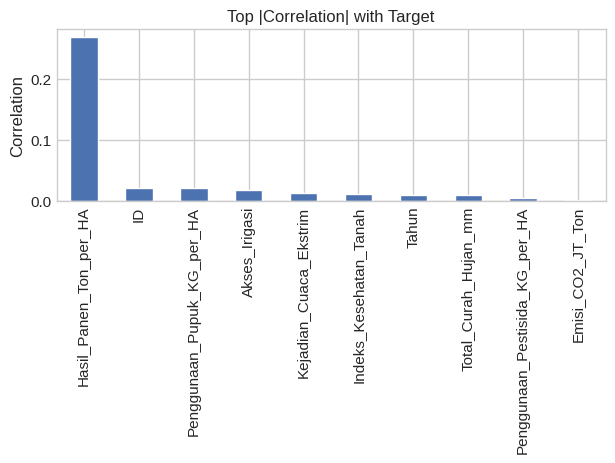

In [12]:
# Cell 9: Pearson corr with target
if target is not None and pd.api.types.is_numeric_dtype(train[target]) and len(num_cols)>0:
    corr = train[num_cols + [target]].corr(numeric_only=True)[target].sort_values(ascending=False)
    corr_df = corr.drop(labels=[target], errors="ignore").reset_index()
    corr_df.columns = ["feature", "corr_with_target"]
    display(corr_df)

    # Bar plot top 15 |corr|
    topN = corr.abs().drop(labels=[target], errors="ignore").sort_values(ascending=False).head(15)
    plt.figure()
    topN.plot(kind="bar")
    plt.title("Top |Correlation| with Target")
    plt.ylabel("Correlation")
    plt.tight_layout()
    plt.show()

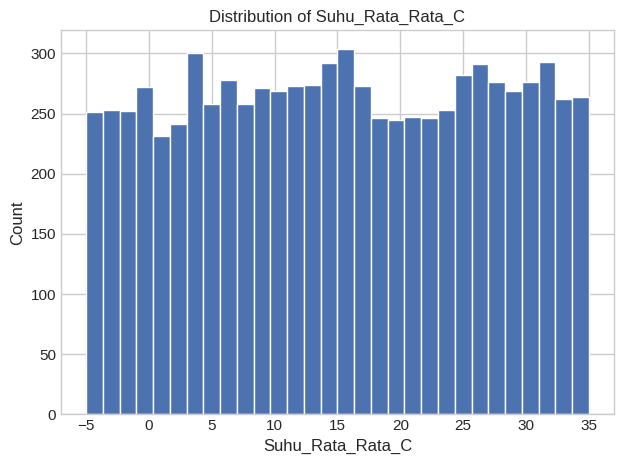

In [13]:
# Cell 10: Target distribution
if target is not None and pd.api.types.is_numeric_dtype(train[target]):
    plt.figure()
    train[target].hist(bins=30)
    plt.title(f"Distribution of {target}")
    plt.xlabel(target); plt.ylabel("Count")
    plt.tight_layout(); plt.show()

In [14]:
# Cell 11: Find year/region and domain drivers
def find_col(candidates, columns):
    for key in candidates:
        for c in columns:
            if re.search(key, c, flags=re.I): return c
    return None

cols = list(train.columns)
year_col   = find_col(["tahun","year"], cols)
region_col = find_col(["wilayah","region","provinsi","province","kabupaten","district","kota"], cols)

driver_keywords = {
    "curah_hujan": ["curah","rain","precip"],
    "emisi_co2":   ["co2","emisi","emission"],
    "ekstrem":     ["ekstrem","extreme","storm","heatwave","flood","drought"],
    "hasil_panen": ["hasil","yield"],
    "pupuk":       ["pupuk","fertilizer","fertiliser"],
    "irigasi":     ["irigasi","irrigation"],
}
driver_cols = {}
for k, keys in driver_keywords.items():
    c = find_col(keys, cols)
    if c and c != target:
        driver_cols[k] = c

print("year_col:", year_col)
print("region_col:", region_col)
print("driver_cols:", driver_cols)

year_col: Tahun
region_col: Wilayah
driver_cols: {'curah_hujan': 'Total_Curah_Hujan_mm', 'emisi_co2': 'Emisi_CO2_JT_Ton', 'hasil_panen': 'Hasil_Panen_Ton_per_HA', 'pupuk': 'Penggunaan_Pupuk_KG_per_HA', 'irigasi': 'Akses_Irigasi'}


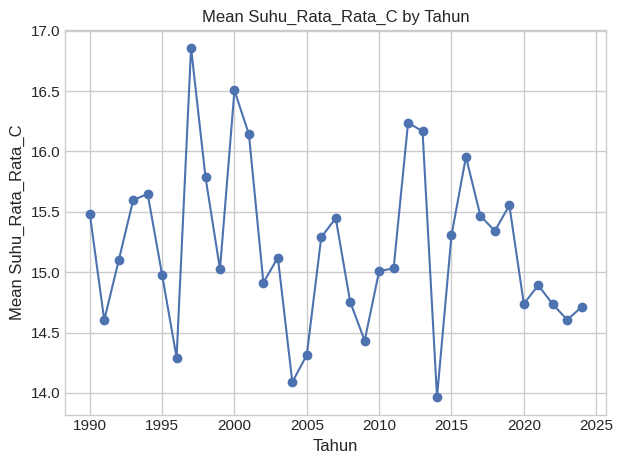

In [15]:
# Cell 12: Time trend of target (global)
if target and year_col and pd.api.types.is_numeric_dtype(train[target]):
    g = train.groupby(year_col)[target].mean().sort_index()
    plt.figure()
    g.plot(marker="o")
    plt.title(f"Mean {target} by {year_col}")
    plt.xlabel(year_col); plt.ylabel(f"Mean {target}")
    plt.tight_layout(); plt.show()

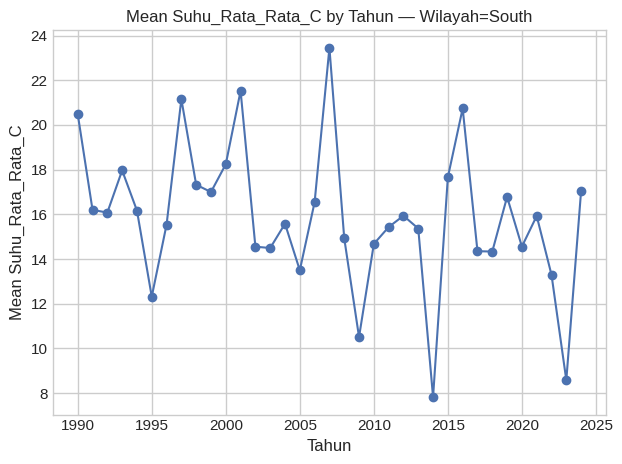

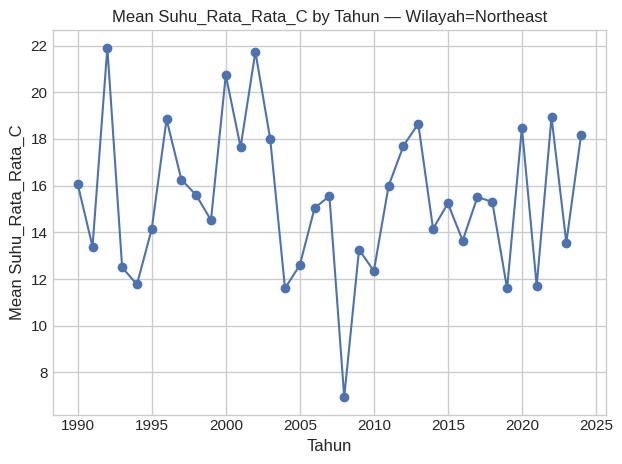

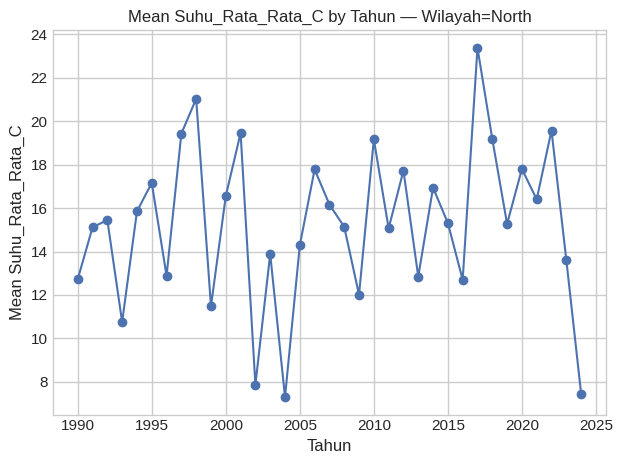

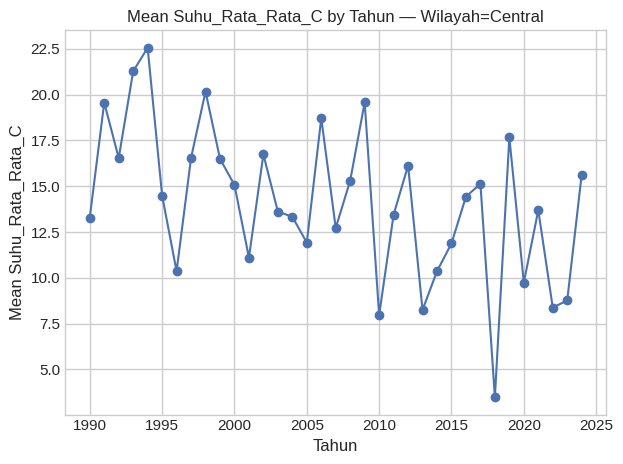

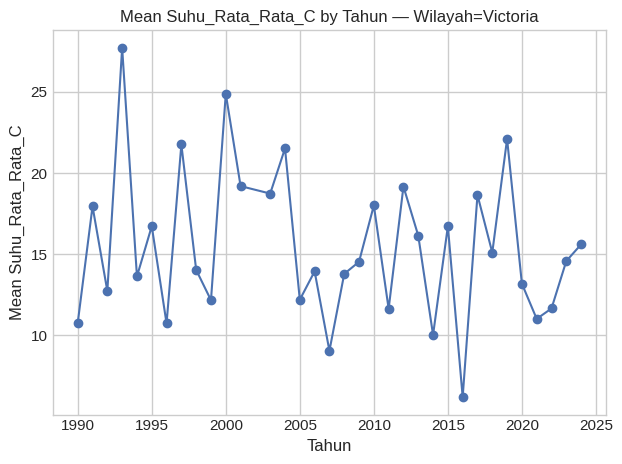

In [16]:
# Cell 13: Time trend per top regions
if target and year_col and region_col and pd.api.types.is_numeric_dtype(train[target]):
    top_regions = train[region_col].value_counts().head(5).index.tolist()
    for r in top_regions:
        s = train.loc[train[region_col]==r].groupby(year_col)[target].mean().sort_index()
        plt.figure()
        s.plot(marker="o")
        plt.title(f"Mean {target} by {year_col} — {region_col}={r}")
        plt.xlabel(year_col); plt.ylabel(f"Mean {target}")
        plt.tight_layout(); plt.show()

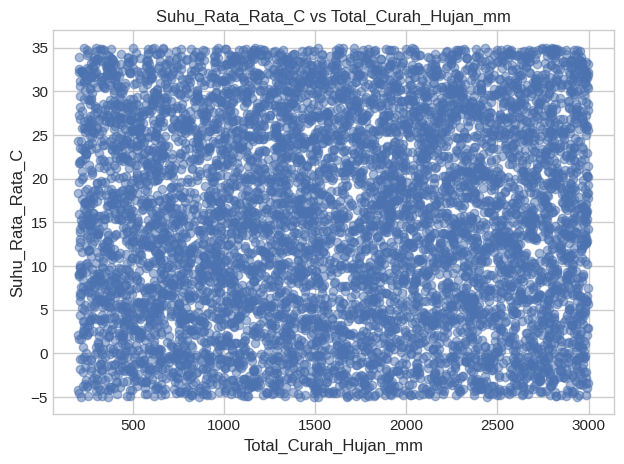

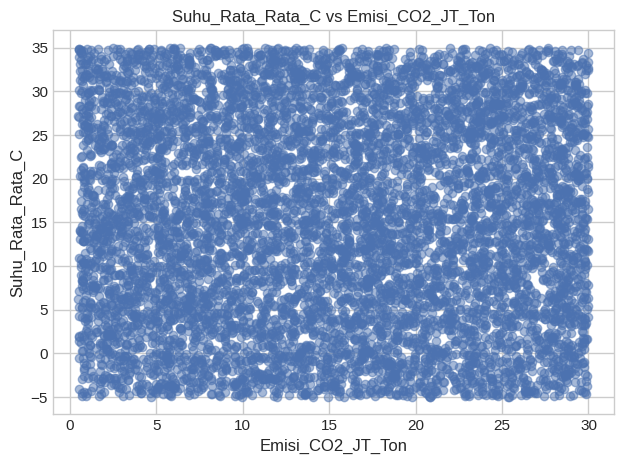

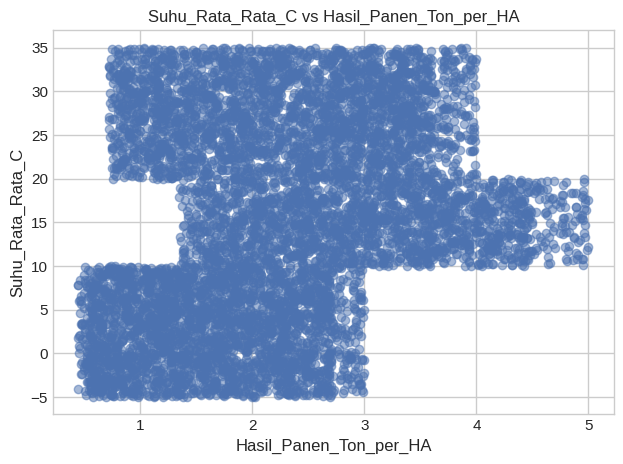

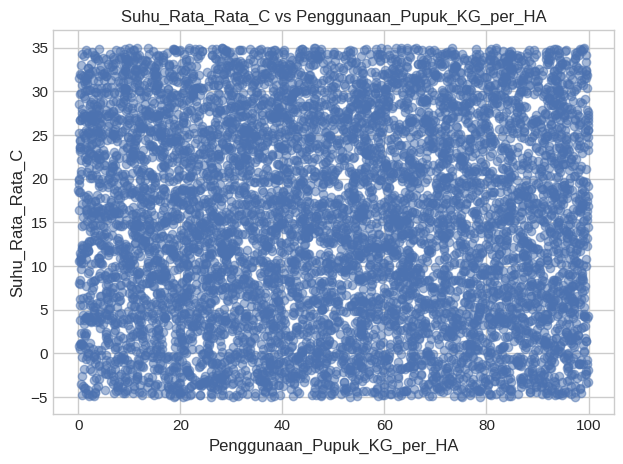

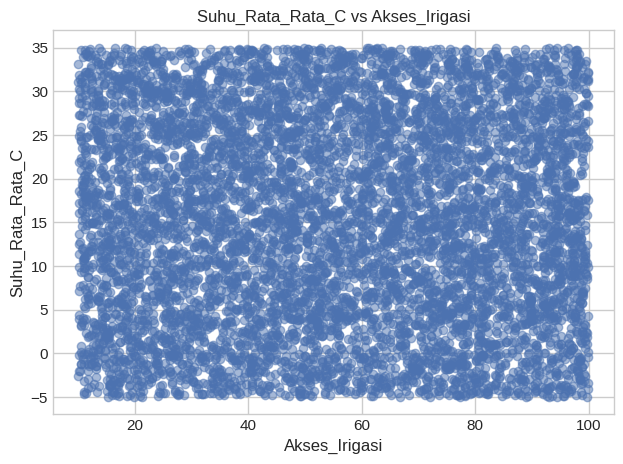

In [17]:
# Cell 14: Scatter target vs domain driver features
if target and pd.api.types.is_numeric_dtype(train[target]):
    for name, c in driver_cols.items():
        if c in train.columns and pd.api.types.is_numeric_dtype(train[c]):
            plt.figure()
            plt.scatter(train[c], train[target], alpha=0.5)
            plt.title(f"{target} vs {c}")
            plt.xlabel(c); plt.ylabel(target)
            plt.tight_layout(); plt.show()

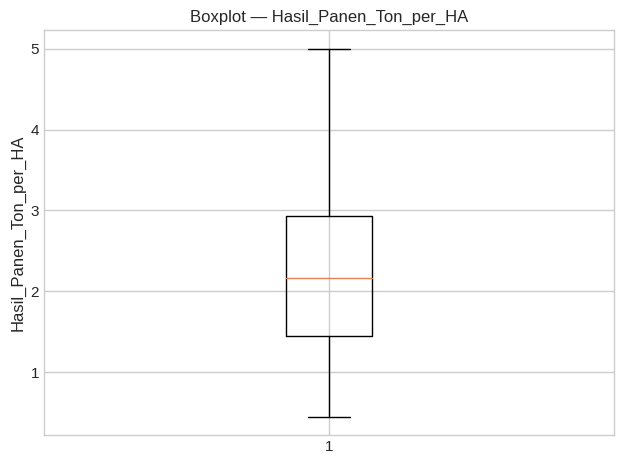

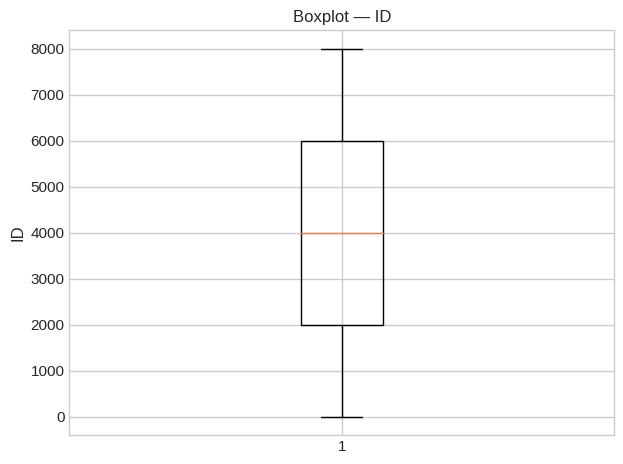

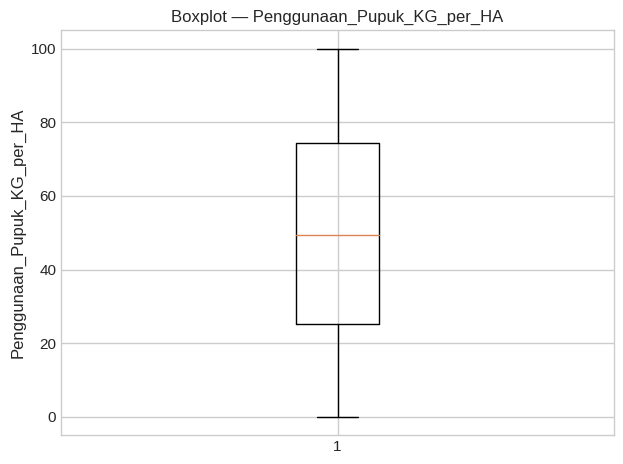

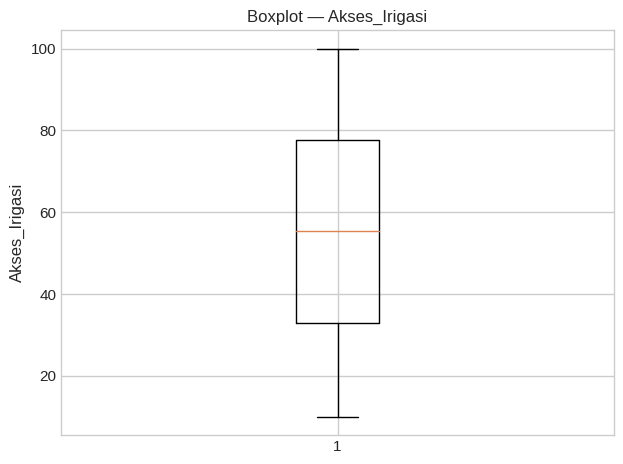

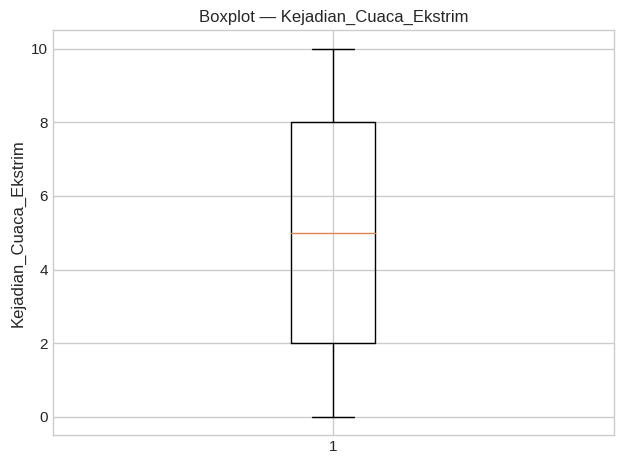

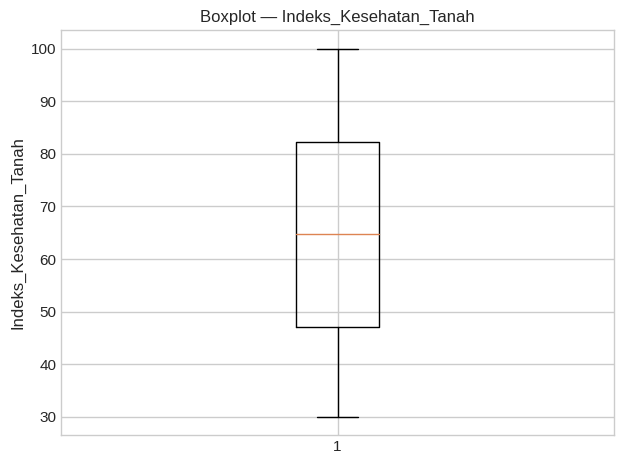

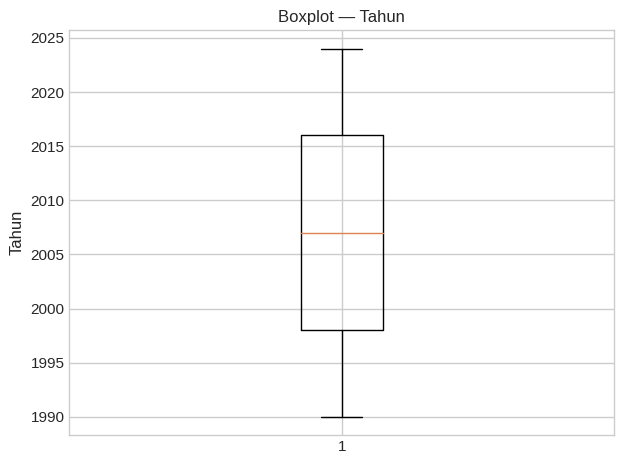

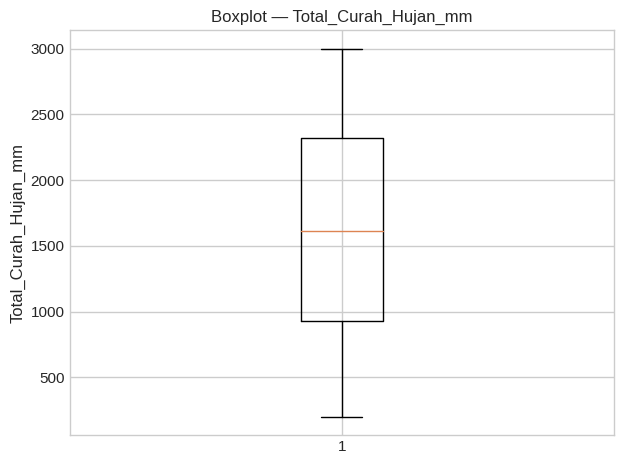

In [18]:
# Cell 15: Outlier inspection (boxplots)
NUM_TO_CHECK = 8
key_nums = [c for c in num_cols if c != target]
if target and len(num_cols)>0 and pd.api.types.is_numeric_dtype(train[target]):
    corr_abs = train[num_cols + [target]].corr(numeric_only=True)[target].abs().drop(labels=[target], errors="ignore")
    key_nums = corr_abs.sort_values(ascending=False).head(NUM_TO_CHECK).index.tolist()
else:
    key_nums = key_nums[:NUM_TO_CHECK]

for c in key_nums:
    if pd.api.types.is_numeric_dtype(train[c]):
        plt.figure()
        plt.boxplot(train[c].dropna().values, vert=True)
        plt.title(f"Boxplot — {c}")
        plt.ylabel(c)
        plt.tight_layout(); plt.show()